# push_t_book_1 — PushT figures for the book

Book versions of the PushT / LeWorldModel visuals from the JEPA video.

Instead of recoloring the pygame pixel frames (what the video pipeline did), these figures are
**re-rendered as vector shapes directly from the dataset `state` vectors**, using the exact geometry
from `stable_worldmodel/envs/pusht/env.py`. That gives crisp, print-ready SVG/PDF output with exact
palette colors and no anti-aliasing fringe.

Geometry recovered from the env source:
- `state = [agent_x, agent_y, block_x, block_y, block_angle, agent_vx, agent_vy]` in a 512×512 world (y down)
- T block: scale 30, length 4 → bar 120×30, stem 30×90, body origin at the bottom-center of the bar
- Effector (agent): circle, radius `0.375 × 40 = 15`
- Goal T: fixed at `(256, 256)`, angle `π/4`

Sections:
1. Config (colors, episode, stride, output dir)
2. Setup (dataset)
3. Vector renderer + sanity check against the real pixel frame
4. Episode browser
5. Render gameplay strip for the chosen episode


```
pip install stable-worldmodel
pip install h5py hdf5plugin

pip install -U "huggingface_hub[cli]" zstd      # zstd via brew if pip balks: brew install zstd

mkdir -p ~/.stable_worldmodel/datasets
hf download quentinll/lewm-pusht --repo-type dataset \
   --local-dir ~/.stable_worldmodel/datasets/_dl

zstd -d ~/.stable_worldmodel/datasets/_dl/pusht_expert_train.h5.zst \
     -o ~/.stable_worldmodel/datasets/pusht_expert_train.h5
     
```

## 1. Config

In [1]:
from pathlib import Path

# ── Print palette ──────────────────────────────────────────────────────────
CHILL_BROWN = "#948678"
LT_BLUE     = "#5badb6"
ORANGE      = "#eb8423"
FRESH_TAN   = "#f4ebd9"

PALETTE = dict(
    target     = CHILL_BROWN,   # goal / target T
    movable    = LT_BLUE,       # the T being pushed
    effector   = ORANGE,        # the circular pusher
    background = FRESH_TAN,
    outline    = None,          # e.g. "#000000" to add thin outlines on the shapes; None = flat fills
    frame      = CHILL_BROWN,   # color of the box around each frame; None = no box
    frame_width = 1.5,          # stroke width of that box, in points
)

# ── Episode / frames ───────────────────────────────────────────────────────
EPISODE_ID   = 18002 #2167 #18002   # which human/expert episode to render (same indexing as the video notebooks)
FRAME_STRIDE = 1 #15      # render every N-th frame
START_STEP   = 0       # first frame to render (within the episode)
END_STEP     = None    # None = run to end of episode
INCLUDE_LAST = True    # always include the final frame of the episode even if off-stride

# ── Output ─────────────────────────────────────────────────────────────────
OUT_ROOT = Path("/Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/4_jepa/graphics")
OUT_DIR  = OUT_ROOT / f"ep_{EPISODE_ID:05d}_stride{FRAME_STRIDE}"
SAVE_FORMATS = ["svg"] #, "pdf", "png"]   # per-frame exports
PNG_DPI = 300


## 2. Setup

In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Circle, Rectangle
from PIL import Image
import stable_worldmodel as swm

ds = swm.data.HDF5Dataset(name="pusht_expert_train",
                          keys_to_cache=["action", "proprio", "state"])
ep_lens   = np.asarray(ds.lengths, dtype=np.int64)
ep_starts = np.concatenate([[0], np.cumsum(ep_lens)[:-1]])

print(f"episodes: {len(ep_lens)}   frames: {len(ds)}")
print(f"ep length  min={ep_lens.min()}  median={int(np.median(ep_lens))}  max={ep_lens.max()}")

def episode_states(ep_id):
    """(ep_len, 7) float32 state array for one episode."""
    row0, n = int(ep_starts[ep_id]), int(ep_lens[ep_id])
    return np.stack([ds[row0 + t]["state"].squeeze(0).cpu().numpy() for t in range(n)]).astype(np.float32)

def episode_pixels(ep_id, t):
    """(224, 224, 3) uint8 pixel frame from the dataset (for sanity checks only)."""
    return ds[int(ep_starts[ep_id]) + t]["pixels"].squeeze(0).permute(1, 2, 0).cpu().numpy()


episodes: 18685   frames: 2336736
ep length  min=49  median=123  max=246


## 3. Vector renderer

In [3]:
# ── PushT geometry (from stable_worldmodel/envs/pusht/env.py) ──────────────
WORLD        = 512                             # pygame window size; state coords live here
GOAL_POSE    = np.array([256.0, 256.0, np.pi / 4])
AGENT_RADIUS = 0.375 * 40                      # add_circle: base_radius * scale
T_SCALE, T_LEN = 30, 4                         # add_tee hard-codes scale=30, length=4

# pymunk builds the T from two rectangles (bar: 120×30, stem: 30×90). Drawing those as two
# patches leaves a hairline anti-aliasing seam where they meet, so we draw the union outline
# as ONE polygon instead. Local coords, body origin at the bottom-center of the bar:
_S, _L = T_SCALE, T_LEN * T_SCALE
_T_OUTLINE = np.array([
    (-_L/2, 0), (_L/2, 0), (_L/2, _S),          # bar: bottom-left → bottom-right → up
    (_S/2, _S), (_S/2, _L),                      # across to stem, down the stem
    (-_S/2, _L), (-_S/2, _S),                    # stem bottom, back up
    (-_L/2, _S),                                 # across to bar left
], float)

def tee_world_vertices(x, y, angle):
    """Local → world, same as pymunk body.local_to_world (rotate then translate)."""
    c, s = np.cos(angle), np.sin(angle)
    R = np.array([[c, -s], [s, c]])
    return (_T_OUTLINE @ R.T) + (x, y)

def draw_tee(ax, pose, color, outline=None, zorder=1):
    ax.add_patch(Polygon(tee_world_vertices(*pose), closed=True, facecolor=color,
                         edgecolor=outline if outline else color,
                         linewidth=0.8 if outline else 0,
                         joinstyle="miter", zorder=zorder))

def render_state(state, ax=None, palette=PALETTE, show_goal=True, show_effector=True, figsize=3.0):
    """Draw one PushT frame from a 7-d (or 5-d) state vector onto `ax`."""
    created = ax is None
    if created:
        fig, ax = plt.subplots(figsize=(figsize, figsize))
        fig.patch.set_facecolor(palette["background"])
    ax.set_facecolor(palette["background"])
    # arena box: background fill + optional stroke, drawn on top so the stroke covers shape edges
    if palette.get("frame"):
        ax.add_patch(Rectangle((0, 0), WORLD, WORLD, facecolor="none",
                               edgecolor=palette["frame"], linewidth=palette.get("frame_width", 1.5),
                               joinstyle="miter", clip_on=False, zorder=10))
    if show_goal:
        draw_tee(ax, GOAL_POSE, palette["target"], palette["outline"], zorder=1)
    draw_tee(ax, (state[2], state[3], state[4]), palette["movable"], palette["outline"], zorder=2)
    if show_effector:
        ax.add_patch(Circle((state[0], state[1]), AGENT_RADIUS,
                            facecolor=palette["effector"],
                            edgecolor=palette["outline"] if palette["outline"] else palette["effector"],
                            linewidth=0.8 if palette["outline"] else 0, zorder=3))
    ax.set_xlim(0, WORLD); ax.set_ylim(WORLD, 0)     # y down, matching pygame / imshow
    ax.set_aspect("equal"); ax.axis("off")
    return ax

def save_fig(fig, path_stem, formats=SAVE_FORMATS, dpi=PNG_DPI, bg=None):
    bg = bg if bg is not None else PALETTE["background"]
    for fmt in formats:
        fig.savefig(f"{path_stem}.{fmt}", dpi=dpi, facecolor=bg, bbox_inches="tight", pad_inches=0.02)


### Sanity check: vector render vs. dataset pixel frame

Left: the real 224×224 frame from the dataset. Middle: our vector render. Right: vector outlines
overlaid on the pixel frame — the shapes should sit exactly on top of the original.

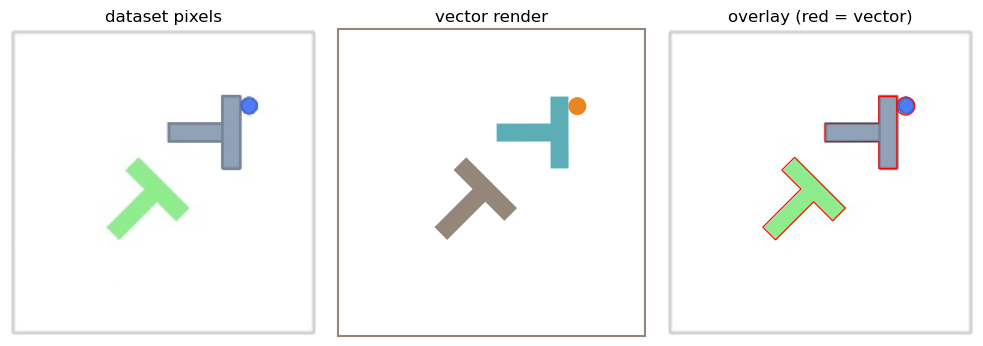

state: [399.14 128.1  384.36 172.13   1.57 -72.63 -53.8 ]


In [4]:
ep_states = episode_states(EPISODE_ID)
t_check   = min(40, len(ep_states) - 1)
px        = episode_pixels(EPISODE_ID, t_check)
st        = ep_states[t_check]

fig, axs = plt.subplots(1, 3, figsize=(10, 3.4))
axs[0].imshow(px); axs[0].set_title("dataset pixels"); axs[0].axis("off")
render_state(st, ax=axs[1]); axs[1].set_title("vector render")

axs[2].imshow(px, extent=(0, WORLD, WORLD, 0))      # stretch 224 px frame onto 512 world coords
overlay = dict(target="none", movable="none", effector="none", background="none", outline="#ff0000", frame=None)
render_state(st, ax=axs[2], palette=overlay); axs[2].set_title("overlay (red = vector)")
plt.tight_layout(); plt.show()
print("state:", st.round(2))


## 4. Episode browser
Quick way to shop for a good episode: first / middle / last frame of a handful of episodes.

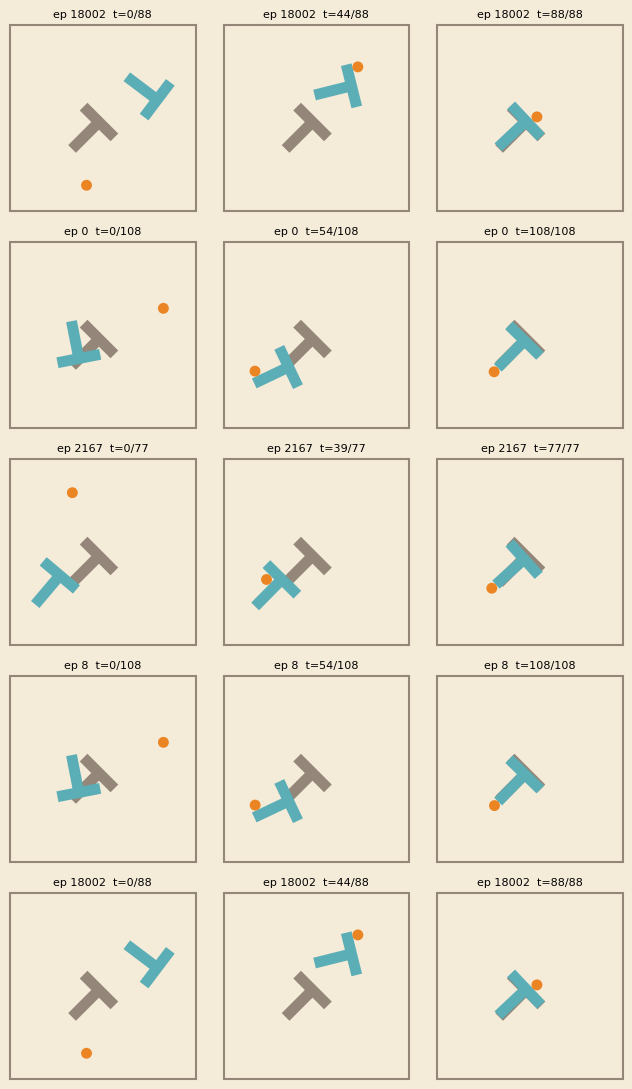

In [5]:
def browse_episodes(ep_ids, figsize_per=2.2):
    fig, axs = plt.subplots(len(ep_ids), 3, figsize=(3 * figsize_per, len(ep_ids) * figsize_per))
    axs = np.atleast_2d(axs)
    for r, ep in enumerate(ep_ids):
        s = episode_states(ep); n = len(s)
        for c, t in enumerate([0, n // 2, n - 1]):
            render_state(s[t], ax=axs[r, c])
            axs[r, c].set_title(f"ep {ep}  t={t}/{n-1}", fontsize=8)
    fig.patch.set_facecolor(PALETTE["background"])
    plt.tight_layout(); plt.show()

browse_episodes([EPISODE_ID, 0, 2167, 8, 18002][:5])


## 5. Render gameplay strip for `EPISODE_ID`

episode 18002: 89 frames → rendering 89 frames: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88]


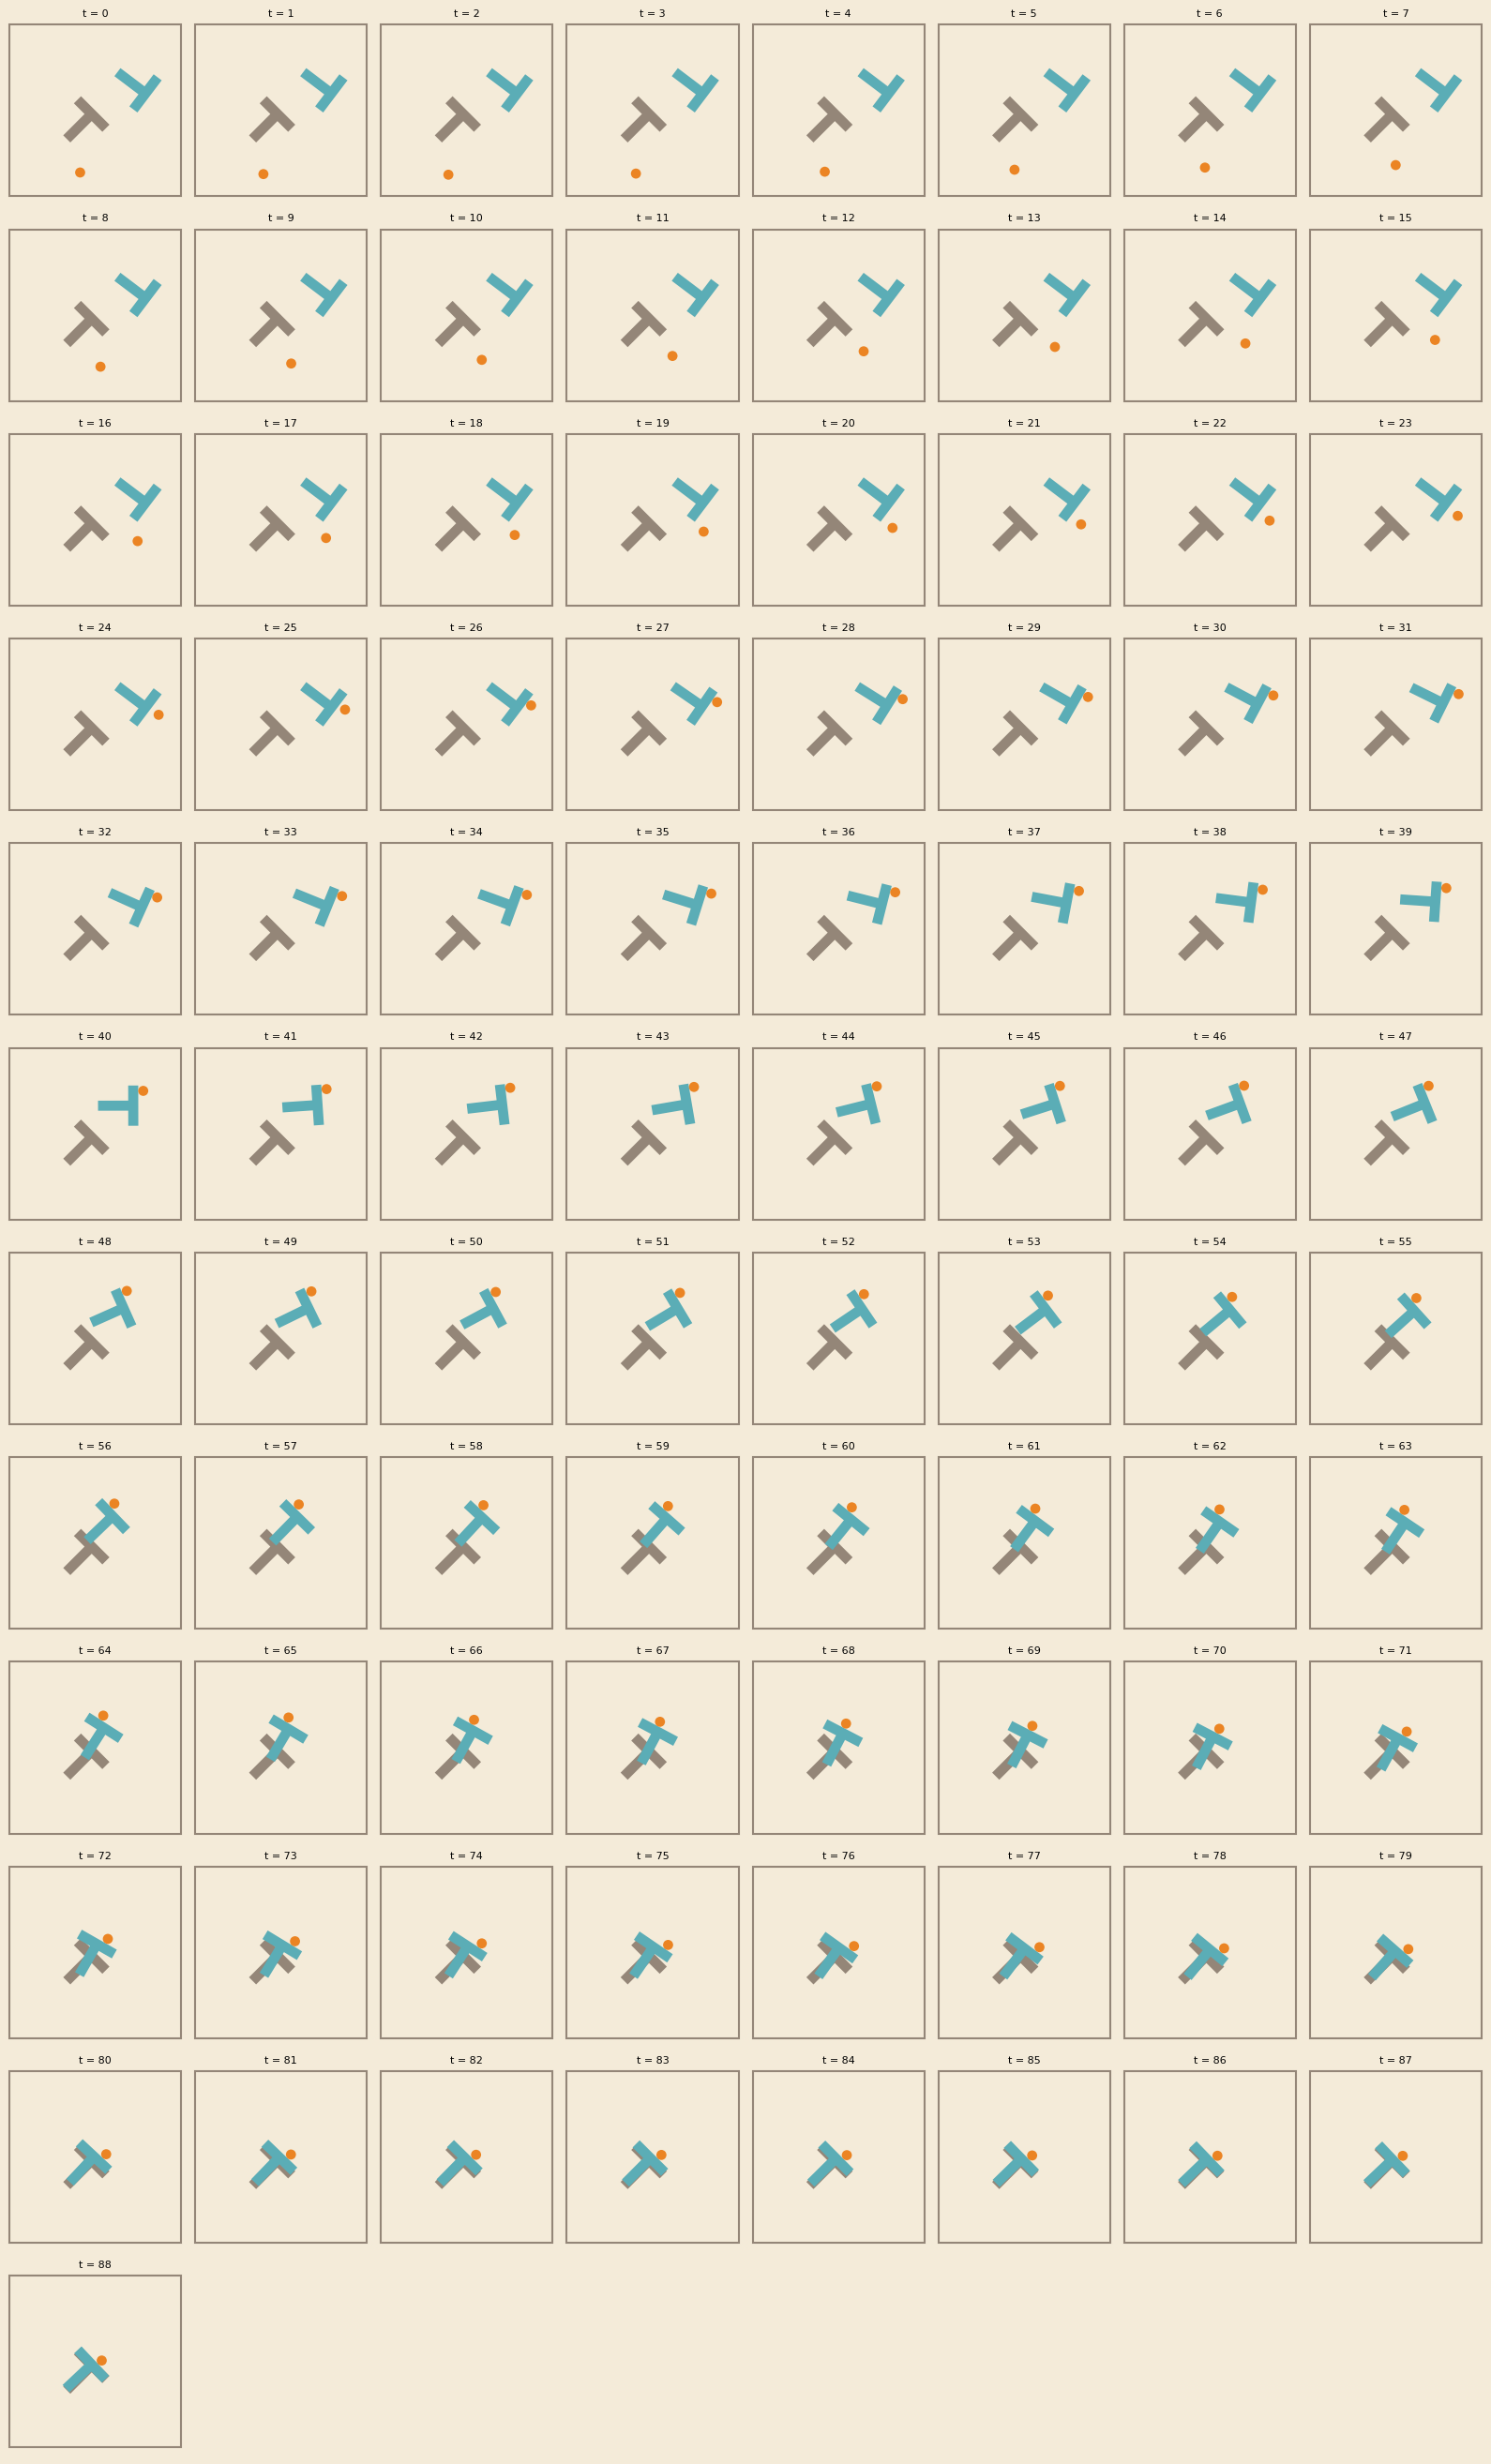

In [6]:
ep_states = episode_states(EPISODE_ID)
n_frames  = len(ep_states)
end       = n_frames - 1 if END_STEP is None else min(END_STEP, n_frames - 1)

frame_ids = list(range(START_STEP, end + 1, FRAME_STRIDE))
if INCLUDE_LAST and frame_ids[-1] != end:
    frame_ids.append(end)

print(f"episode {EPISODE_ID}: {n_frames} frames → rendering {len(frame_ids)} frames: {frame_ids}")

# ── Preview as a grid ──────────────────────────────────────────────────────
n_cols = min(8, len(frame_ids))
n_rows = int(np.ceil(len(frame_ids) / n_cols))
fig, axs = plt.subplots(n_rows, n_cols, figsize=(2.0 * n_cols, 2.2 * n_rows))
axs = np.atleast_1d(axs).ravel()
for ax, t in zip(axs, frame_ids):
    render_state(ep_states[t], ax=ax)
    ax.set_title(f"t = {t}", fontsize=8)
for ax in axs[len(frame_ids):]:
    ax.axis("off")
fig.patch.set_facecolor(PALETTE["background"])
plt.tight_layout(); plt.show()


### Export
Each selected frame is written as an individual SVG / PDF / PNG (square, no margins) so they can be
laid out freely in InDesign/Illustrator, plus one combined horizontal strip and the raw states/actions.



saved /Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/4_jepa/graphics/ep_18002_stride1/strip_vertical.svg   (89 frames, top → bottom)


In [7]:
# ── Vertical strip of the selected frames → single SVG ─────────────────────
STRIP_FRAME_SIZE = 2.0      # inches per frame (square)
STRIP_GAP        = 0.12     # vertical gap between frames, in inches

LABEL_FONT   = "Helvetica"          # any installed sans; falls back to DejaVu Sans
LABEL_SIZE   = 12                    # points
LABEL_COLOR  = PALETTE["target"]    # chill brown
LABEL_INSET  = 14                   # distance from the frame's edges, in world px (0–512)
LABEL_FMT    = "{t}"                # e.g. "t = {t}" or "step {t}"

n   = len(frame_ids)
gap = STRIP_GAP / STRIP_FRAME_SIZE
fig = plt.figure(figsize=(STRIP_FRAME_SIZE, n * STRIP_FRAME_SIZE + (n - 1) * STRIP_GAP))
fig.patch.set_alpha(0)               # transparent between frames

for i, t in enumerate(frame_ids):
    bottom = (n - 1 - i) * (1 + gap) / (n + (n - 1) * gap)
    height = 1 / (n + (n - 1) * gap)
    ax = fig.add_axes([0, bottom, 1, height])
    ax.patch.set_alpha(0)
    ax.add_patch(Rectangle((0, 0), WORLD, WORLD, facecolor=PALETTE["background"],
                           edgecolor="none", zorder=0))
    render_state(ep_states[t], ax=ax)
    ax.set_facecolor("none")
    # step number, bottom-right corner (data coords: y is flipped, so WORLD = bottom)
    ax.text(WORLD - LABEL_INSET, WORLD - LABEL_INSET, LABEL_FMT.format(t=t),
            fontfamily=[LABEL_FONT, "DejaVu Sans"], fontweight="bold", fontsize=LABEL_SIZE,
            color=LABEL_COLOR, ha="right", va="bottom", zorder=11)

OUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / "strip_vertical.svg", transparent=True,
            bbox_inches="tight", pad_inches=0.02)
plt.show()
print(f"saved {OUT_DIR / 'strip_vertical.svg'}   ({n} frames, top → bottom)")

## Scratch



saved /Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/4_jepa/graphics/ep_18002_stride1/strip_vertical.svg   (89 frames, top → bottom)


In [8]:
# ── Vertical strip of the selected frames → single SVG ─────────────────────
STRIP_FRAME_SIZE = 2.0      # inches per frame (square)
STRIP_GAP        = 0.12     # vertical gap between frames, in inches

LABEL_FONT   = "Helvetica"          # any installed sans; falls back to DejaVu Sans
LABEL_SIZE   = 9                    # points
LABEL_COLOR  = PALETTE["target"]    # chill brown
LABEL_INSET  = 14                   # distance from the frame's edges, in world px (0–512)
LABEL_FMT    = "{t}"                # e.g. "t = {t}" or "step {t}"

n   = len(frame_ids)
gap = STRIP_GAP / STRIP_FRAME_SIZE
fig = plt.figure(figsize=(STRIP_FRAME_SIZE, n * STRIP_FRAME_SIZE + (n - 1) * STRIP_GAP))
fig.patch.set_alpha(0)               # transparent between frames

for i, t in enumerate(frame_ids):
    bottom = (n - 1 - i) * (1 + gap) / (n + (n - 1) * gap)
    height = 1 / (n + (n - 1) * gap)
    ax = fig.add_axes([0, bottom, 1, height])
    ax.patch.set_alpha(0)
    ax.add_patch(Rectangle((0, 0), WORLD, WORLD, facecolor=PALETTE["background"],
                           edgecolor="none", zorder=0))
    render_state(ep_states[t], ax=ax)
    ax.set_facecolor("none")
    # step number, bottom-right corner (data coords: y is flipped, so WORLD = bottom)
    ax.text(WORLD - LABEL_INSET, WORLD - LABEL_INSET, LABEL_FMT.format(t=t),
            fontfamily=[LABEL_FONT, "DejaVu Sans"], fontweight="bold", fontsize=LABEL_SIZE,
            color=LABEL_COLOR, ha="right", va="bottom", zorder=11)

OUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / "strip_vertical.svg", transparent=True,
            bbox_inches="tight", pad_inches=0.02)
plt.show()
print(f"saved {OUT_DIR / 'strip_vertical.svg'}   ({n} frames, top → bottom)")



saved /Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/4_jepa/graphics/ep_18002_stride1/strip_horizontal.svg   (89 frames, left → right)


In [9]:
# ── Horizontal strip of the selected frames → single SVG ───────────────────
STRIP_FRAME_SIZE = 2.0      # inches per frame (square)
STRIP_GAP        = 0.12     # horizontal gap between frames, in inches

LABEL_FONT   = "Helvetica"          # any installed sans; falls back to DejaVu Sans
LABEL_SIZE   = 12                    # points
LABEL_COLOR  = PALETTE["target"]    # chill brown
LABEL_INSET  = 14                   # distance from the frame's edges, in world px (0–512)
LABEL_FMT    = "{t}"                # e.g. "t = {t}" or "step {t}"

n   = len(frame_ids)
gap = STRIP_GAP / STRIP_FRAME_SIZE
fig = plt.figure(figsize=(n * STRIP_FRAME_SIZE + (n - 1) * STRIP_GAP, STRIP_FRAME_SIZE))
fig.patch.set_alpha(0)

for i, t in enumerate(frame_ids):
    left  = i * (1 + gap) / (n + (n - 1) * gap)
    width = 1 / (n + (n - 1) * gap)
    ax = fig.add_axes([left, 0, width, 1])
    ax.patch.set_alpha(0)
    ax.add_patch(Rectangle((0, 0), WORLD, WORLD, facecolor=PALETTE["background"],
                           edgecolor="none", zorder=0))
    render_state(ep_states[t], ax=ax)
    ax.set_facecolor("none")
    # step number, bottom-right corner (data coords: y is flipped, so WORLD = bottom)
    ax.text(WORLD - LABEL_INSET, WORLD - LABEL_INSET, LABEL_FMT.format(t=t),
            fontfamily=[LABEL_FONT, "DejaVu Sans"], fontweight="bold", fontsize=LABEL_SIZE,
            color=LABEL_COLOR, ha="right", va="bottom", zorder=11)

OUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / "strip_horizontal.svg", transparent=True,
            bbox_inches="tight", pad_inches=0.02)
plt.show()
print(f"saved {OUT_DIR / 'strip_horizontal.svg'}   ({n} frames, left → right)")